# Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf

import matplotlib.pyplot as plt
import datetime

import warnings
warnings.filterwarnings("ignore")

In [2]:
stock = "IBM"
start = datetime.datetime(2025, 1, 1)
end = datetime.datetime(2025, 9, 15)
ticker = yf.download(stock, start, end)
stock_data = pd.DataFrame(ticker['Close'][stock])
stock_data.columns = ['Price']
stock_data.head()

[*********************100%***********************]  1 of 1 completed


,Price
Date,
2025-01-02,215.582550
2025-01-03,218.238846
2025-01-06,218.258453
2025-01-07,219.522903
2025-01-08,218.758347


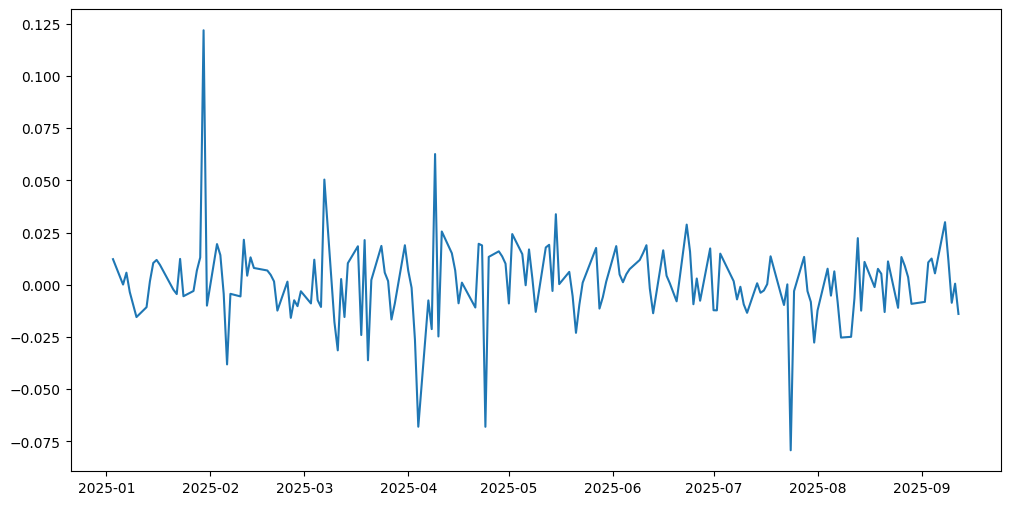

In [4]:
stock_data['return'] = np.log(stock_data['Price'] / stock_data['Price'].shift(1))
plt.figure(figsize=(12, 6))
plt.plot(stock_data['return'])
plt.show()

In [5]:
stock_data['move'] = stock_data['Price'] - stock_data['Price'].shift(1)
stock_data['up'] = np.where(stock_data['move'] > 0, stock_data['move'], 0)
stock_data['down'] = np.where(stock_data['move'] < 0, stock_data['move'], 0)

In [6]:
stock_data.head()

,Price,return,move,up,down
Date,,,,,
2025-01-02,215.582550,NaN,NaN,0.000000,0.000000
2025-01-03,218.238846,0.012246,2.656296,2.656296,0.000000
2025-01-06,218.258453,0.000090,0.019608,0.019608,0.000000
2025-01-07,219.522903,0.005777,1.264450,1.264450,0.000000
2025-01-08,218.758347,-0.003489,-0.764557,0.000000,-0.764557


In [9]:
stock_data['average_gain'] = stock_data['up'].rolling(14).mean()
stock_data['average_loss'] = stock_data['down'].abs().rolling(14).mean()
stock_data.tail(10)

,Price,return,move,up,down,average_gain,average_loss
Date,,,,,,,
2025-08-29,243.490005,-0.009157,-2.239990,0.000000,-2.239990,1.428573,0.915001
2025-09-02,241.500000,-0.008206,-1.990005,0.000000,-1.990005,1.428573,0.947859
2025-09-03,244.100006,0.010709,2.600006,2.600006,0.000000,1.235716,0.947859
2025-09-04,247.179993,0.012539,3.079987,3.079987,0.000000,1.455715,0.736429
2025-09-05,248.529999,0.005447,1.350006,1.350006,0.000000,1.365715,0.736429
2025-09-08,256.089996,0.029965,7.559998,7.559998,0.000000,1.905715,0.717143
2025-09-09,259.109985,0.011724,3.019989,3.019989,0.000000,1.990714,0.717143
2025-09-10,256.880005,-0.008644,-2.229980,0.000000,-2.229980,1.899999,0.876428
2025-09-11,257.010010,0.000506,0.130005,0.130005,0.000000,1.909285,0.651427


In [10]:

stock_data['rsi'] = 100.0 - (100.0 / (1.0 + (stock_data['average_gain'] / stock_data['average_loss'])))
stock_data.tail()

,Price,return,move,up,down,average_gain,average_loss,rsi
Date,,,,,,,,
2025-09-08,256.089996,0.029965,7.559998,7.559998,0.000000,1.905715,0.717143,72.657941
2025-09-09,259.109985,0.011724,3.019989,3.019989,0.000000,1.990714,0.717143,73.516203
2025-09-10,256.880005,-0.008644,-2.229980,0.000000,-2.229980,1.899999,0.876428,68.433251
2025-09-11,257.010010,0.000506,0.130005,0.130005,0.000000,1.909285,0.651427,74.560708
2025-09-12,253.440002,-0.013988,-3.570007,0.000000,-3.570007,1.717142,0.906428,65.450602


In [11]:
stock_data.head()

,Price,return,move,up,down,average_gain,average_loss,rsi
Date,,,,,,,,
2025-01-02,215.582550,NaN,NaN,0.000000,0.000000,NaN,NaN,NaN
2025-01-03,218.238846,0.012246,2.656296,2.656296,0.000000,NaN,NaN,NaN
2025-01-06,218.258453,0.000090,0.019608,0.019608,0.000000,NaN,NaN,NaN
2025-01-07,219.522903,0.005777,1.264450,1.264450,0.000000,NaN,NaN,NaN
2025-01-08,218.758347,-0.003489,-0.764557,0.000000,-0.764557,NaN,NaN,NaN


In [13]:
stock_data.shape

(174, 8)

In [14]:
stock_data = stock_data.dropna()
stock_data.head()

,Price,return,move,up,down,average_gain,average_loss,rsi
Date,,,,,,,,
2025-01-23,221.561691,0.012375,2.724930,2.724930,0.000000,0.993491,0.566410,63.689383
2025-01-24,220.346252,-0.005501,-1.215439,0.000000,-1.215439,0.993491,0.653227,60.331597
2025-01-27,219.689545,-0.002985,-0.656708,0.000000,-0.656708,0.803756,0.700134,53.445111
2025-01-28,221.189224,0.006803,1.499680,1.499680,0.000000,0.909475,0.700134,56.502844
2025-01-29,224.100388,0.013076,2.911163,2.911163,0.000000,1.027097,0.700134,59.464948


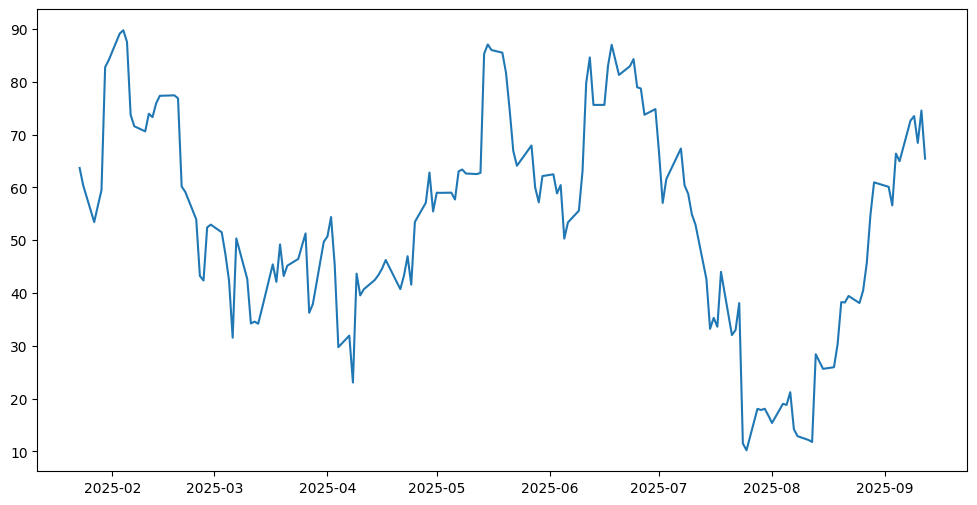

In [15]:
plt.figure(figsize=(12, 6))
plt.plot(stock_data['rsi'])
plt.show()

# RSI

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf

import matplotlib.pyplot as plt
import datetime

import warnings
warnings.filterwarnings("ignore")

[*********************100%***********************]  1 of 1 completed


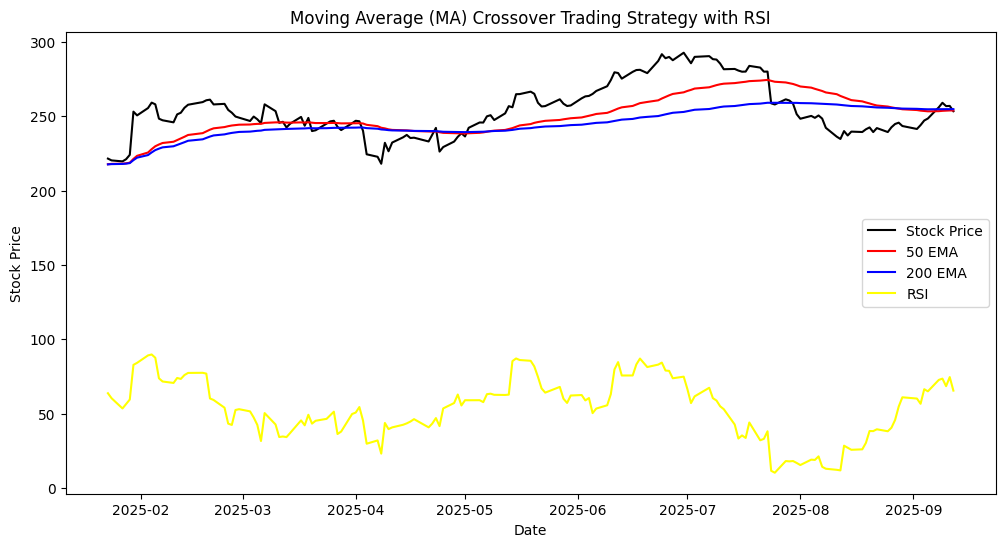

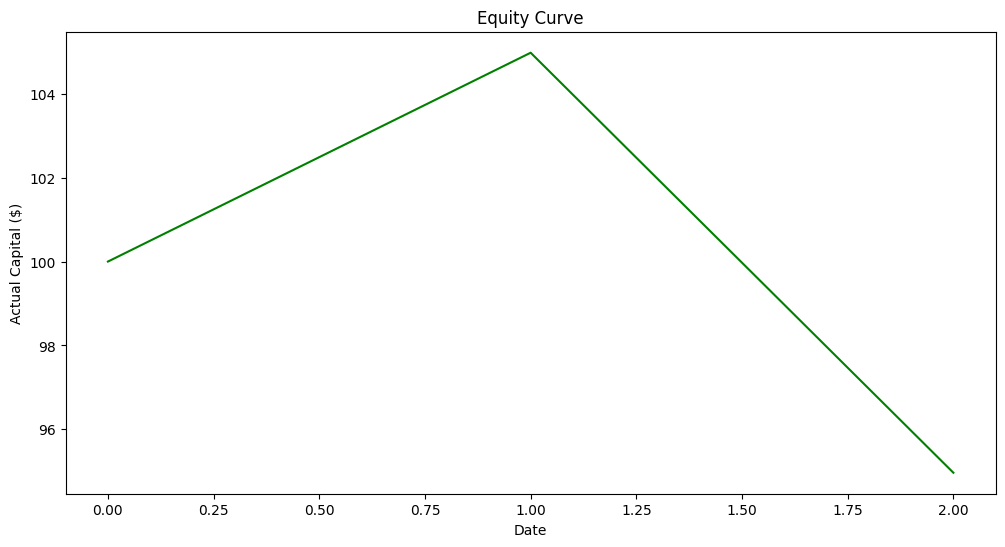

Profit of the trading strategy: -5.04%
Actual Capital: 94.96$
Sharpe Ratio: 0.81
[100, 104.98066603259076, 94.9642613854548]


In [3]:
class MovingAverageRSIStrategy:

    def __init__(self, capital, stock, start, end, short_period, long_period):
        self.data = None
        self.is_long = False
        self.short_period = short_period
        self.long_period = long_period
        self.capital = capital
        self.equity = [capital]
        self.stock = stock
        self.start = start
        self.end = end

    def download_data(self):
        ticker = yf.download(self.stock, self.start, self.end)
        stock_data = pd.DataFrame(ticker['Close'][self.stock])
        stock_data.columns = ['Price']
        self.data = stock_data

    def construct_signals(self):
        self.data['short_ema'] = self.data['Price'].ewm(span=self.short_period).mean()
        self.data['long_ema'] = self.data['Price'].ewm(span=self.long_period).mean()
        self.data["move"] = self.data['Price'] - self.data['Price'].shift(1)
        self.data['up'] = np.where(self.data['move'] > 0, self.data['move'], 0)
        self.data['down'] = np.where(self.data['move'] < 0, self.data['move'], 0)
        self.data['average_gain'] = self.data['up'].rolling(14).mean()
        self.data['average_loss'] = self.data['down'].abs().rolling(14).mean()
        relative_strength = self.data['average_gain'] / self.data['average_loss']
        self.data['rsi'] = 100.0 - (100.0 / (1.0 + relative_strength))
        self.data = self.data.dropna()

    def simulate(self):
        # We consider all the trading days and decide whether to open a long position or not
        price_when_to_buy = 0
        for index, row in self.data.iterrows():
            # Closing the Long Position
            if row.short_ema < row.long_ema and price_when_to_buy > 0 and self.is_long:
                self.equity.append((self.capital * row.Price / price_when_to_buy).item())
                self.is_long = False
                # print("SELL")
            elif row.short_ema > row.long_ema and not self.is_long and row['rsi'] < 30:
                # Open a Long position
                price_when_to_buy = row['Price']
                self.is_long = True
                # print("BUY")
    
    def plot_equity(self):
        plt.figure(figsize=(12, 6))
        plt.title("Equity Curve")
        plt.plot(self.equity, label="Stock Price", color="green")
        plt.xlabel("Date")
        plt.ylabel("Actual Capital ($)")
        plt.show()

    def plot_signals(self):
        plt.figure(figsize=(12, 6))
        plt.plot(self.data['Price'], label="Stock Price", color="black")
        plt.plot(self.data['short_ema'], label=f"{self.short_period} EMA", color="red")
        plt.plot(self.data['long_ema'], label=f"{self.long_period} EMA", color="blue")
        plt.plot(self.data['rsi'], label="RSI", color="yellow")
        plt.title("Moving Average (MA) Crossover Trading Strategy with RSI")
        plt.xlabel("Date")
        plt.ylabel("Stock Price")
        plt.legend(['Stock Price', f"{self.short_period} EMA", f"{self.long_period} EMA", "RSI"])
        plt.show()


    def show_stats(self):
        print("Profit of the trading strategy: %.2f%%" 
            %((float(self.equity[-1]) - float(self.equity[0])) / float(self.equity[0]) * 100))
        print(f"Actual Capital: {self.equity[-1]:.2f}$")


        returns = (self.data['Price'] - self.data['Price'].shift(1)) / self.data['Price'].shift(1)
        sharpe_ratio = returns.mean() / returns.std() * np.sqrt(252)
        print(f"Sharpe Ratio: {sharpe_ratio:.2f}")

if __name__ == "__main__":
    start_date = datetime.datetime(2025, 1, 1)
    end_date = datetime.datetime(2025, 9, 14)

    strategy = MovingAverageRSIStrategy(100, "IBM", start_date, end_date, 50, 200)
    strategy.download_data()
    strategy.construct_signals()
    strategy.plot_signals()
    strategy.simulate()
    strategy.plot_equity()
    strategy.show_stats()
    print(strategy.equity)

In [11]:
max(strategy.data['rsi']), min(strategy.data['rsi'])

(89.76681482887305, 10.206540948686182)